# Mean seasonal cycle — detrended data

Monthly climatology of the detrended field (`../detr_field.nc`): the domain-mean climatology (same method as
`../harmonic.ipynb`), maps of each calendar month's average, and the 12 stacked maps saved
as `mean_seasonal_cycle_detrended.nc`.

In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

FIG_DIR = "../../Figures/climatology"
os.makedirs(FIG_DIR, exist_ok=True)

IN_NC  = "../detr_field.nc"
OUT_NC = "mean_seasonal_cycle_detrended.nc"
TAG    = "detrended"
mnames = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

field = xr.open_dataarray(IN_NC).load()
field

<xarray.DataArray (time: 276, lat: 36, lon: 61)> Size: 5MB
array([[[ 7.30931982e-09,  7.04491035e-09,  6.97955394e-09, ...,
          1.71692682e-09,  2.07423890e-09,  2.19943470e-09],
        [ 7.66150107e-09,  7.38038429e-09,  7.35291612e-09, ...,
          1.52022651e-09,  1.75717402e-09,  2.26803340e-09],
        [ 8.36315640e-09,  8.01065961e-09,  7.84796941e-09, ...,
          1.36457415e-09,  1.79702694e-09,  2.03531459e-09],
        ...,
        [ 1.72270732e-09,  1.86975240e-09,  2.62009085e-09, ...,
         -5.26204910e-09, -5.23588546e-09, -3.91889258e-09],
        [ 7.35035117e-10,  7.41585961e-10, -5.77498074e-10, ...,
         -3.53168552e-09, -4.26821002e-09, -3.76129753e-09],
        [-1.14863935e-10, -1.96917470e-09, -1.95409085e-09, ...,
         -4.65221105e-09, -8.82748051e-10,  2.28060424e-09]],

       [[ 3.31798649e-09,  3.65101573e-09,  3.22342518e-09, ...,
          4.19037973e-10,  2.52768146e-10,  6.49910253e-11],
        [ 4.15585666e-09,  3.52095520e-09,  3.17525168e-09, ...,
          1.36090580e-09,  1.69139315e-09,  1.64451756e-09],
        [ 4.60648472e-09,  3.90408636e-09,  3.66410322e-09, ...,
          1.85467879e-09,  2.31508516e-09,  2.15672928e-09],
...
         -9.81629544e-09, -1.07010514e-08, -1.02514588e-08],
        [-6.16631334e-09, -5.93799757e-09, -6.67011605e-09, ...,
         -9.83872279e-09, -1.03192151e-08, -1.05290483e-08],
        [-6.09770716e-09, -6.15605791e-09, -6.84364917e-09, ...,
         -1.01823930e-08, -9.76024770e-09, -9.82597182e-09]],

       [[-4.92162778e-09, -5.12730791e-09, -6.10685176e-09, ...,
         -5.70360792e-09, -5.50850405e-09, -5.15796281e-09],
        [-6.27180356e-09, -5.52046519e-09, -5.73870757e-09, ...,
         -6.51436980e-09, -5.79859728e-09, -5.63447779e-09],
        [-6.17279679e-09, -5.80086421e-09, -5.41855503e-09, ...,
         -6.31204155e-09, -5.95323754e-09, -5.89005326e-09],
        ...,
        [-6.13498064e-09, -5.90965742e-09, -6.97751704e-09, ...,
         -9.78608748e-09, -1.06701171e-08, -1.02194277e-08],
        [-6.10243118e-09, -5.87506910e-09, -6.61097604e-09, ...,
         -9.80723751e-09, -1.02895159e-08, -1.04983920e-08],
        [-6.03682265e-09, -6.09746262e-09, -6.78460899e-09, ...,
         -1.01538677e-08, -9.73007463e-09, -9.79321562e-09]]],
      shape=(276, 36, 61))
Coordinates:
  * time     (time) datetime64[ns] 2kB 2003-01-01 2003-02-01 ... 2025-12-01
  * lat      (lat) float32 144B 14.5 15.5 16.5 17.5 18.5 ... 46.5 47.5 48.5 49.5
  * lon      (lon) float32 244B -126.5 -125.5 -124.5 ... -68.5 -67.5 -66.5

## Monthly climatology of the domain mean

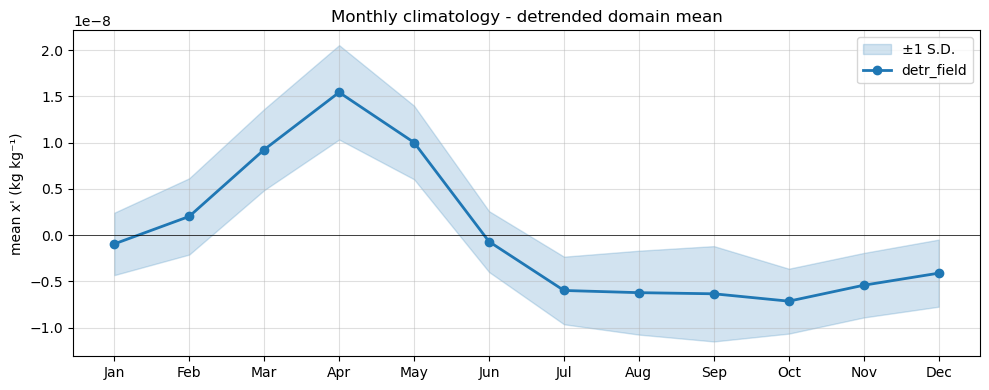

Saved -> ../../Figures/climatology\detrended_domain_mean_monthly_climatology.png
           mean        std
Jan -9.3986e-10 3.3725e-09
Feb  2.0339e-09 4.1234e-09
Mar  9.2545e-09 4.3832e-09
Apr  1.5447e-08 5.1029e-09
May  1.0023e-08 3.9753e-09
Jun -6.8658e-10 3.2886e-09
Jul -5.9712e-09 3.6543e-09
Aug -6.2074e-09 4.5353e-09
Sep -6.3294e-09 5.1530e-09
Oct -7.1265e-09 3.5086e-09
Nov -5.4008e-09 3.4871e-09
Dec -4.0973e-09 3.6266e-09


In [2]:
# Monthly climatology of the detrended field (domain-mean by calendar month)
obs_ts = field.mean(("lat", "lon")).values

month_num = pd.DatetimeIndex(field.time.values).month
obs_by_month = pd.Series(obs_ts, index=month_num).groupby(level=0)
obs_clim = obs_by_month.mean()
obs_std = obs_by_month.std()

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(mnames, obs_clim.values - obs_std.values, obs_clim.values + obs_std.values,
                color="#1f77b4", alpha=0.2, label="±1 S.D.")
ax.plot(mnames, obs_clim.values, "o-", lw=2, color="#1f77b4", label="detr_field")
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("mean x' (kg kg⁻¹)")
ax.set_title("Monthly climatology - detrended domain mean")
ax.legend(); ax.grid(alpha=0.4)
plt.tight_layout()
out = os.path.join(FIG_DIR, f"{TAG}_domain_mean_monthly_climatology.png")
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out)

print(pd.DataFrame({"mean": obs_clim.values, "std": obs_std.values}, index=mnames)
        .to_string(float_format="{:.4e}".format))

## Spatial climatology: average map for each calendar month

In [3]:
# (month, lat, lon): average of all Januaries, all Februaries, ...
clim = field.groupby("time.month").mean("time")
n_years = field.groupby("time.month").count("time").isel(lat=0, lon=0).values
print("Years averaged per month:", dict(zip(mnames, n_years.tolist())))
print("Climatology shape:", clim.shape, clim.dims)
print(f"Range: {float(clim.min()):.4e} - {float(clim.max()):.4e} kg/kg")

# consistency with the domain-mean climatology above
print(f"Max |domain mean of maps - domain-mean climatology| = "
      f"{np.abs(clim.mean(('lat', 'lon')).values - obs_clim.values).max():.3e}")

Years averaged per month: {'Jan': 23, 'Feb': 23, 'Mar': 23, 'Apr': 23, 'May': 23, 'Jun': 23, 'Jul': 23, 'Aug': 23, 'Sep': 23, 'Oct': 23, 'Nov': 23, 'Dec': 23}
Climatology shape: (12, 36, 61) ('month', 'lat', 'lon')
Range: -1.8858e-08 - 2.6061e-08 kg/kg
Max |domain mean of maps - domain-mean climatology| = 1.654e-24


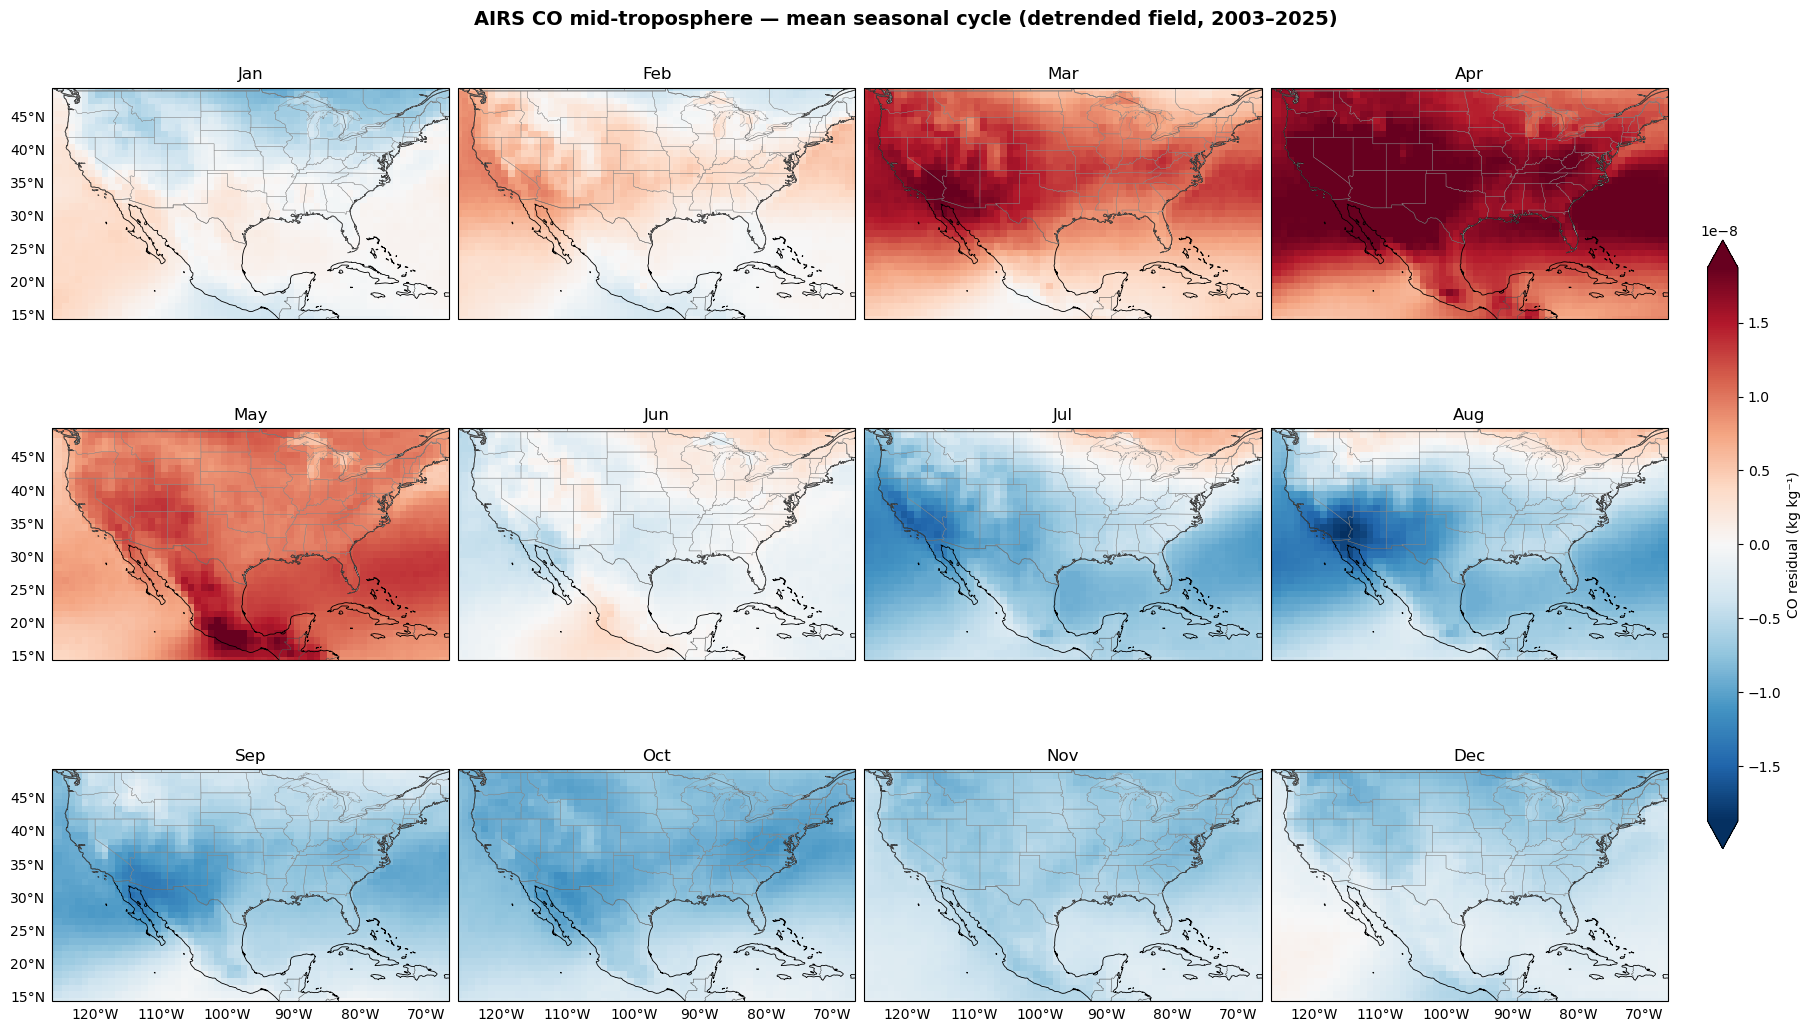

Saved -> ../../Figures/climatology\detrended_monthly_maps.png


In [4]:
lons, lats = clim.lon.values, clim.lat.values
ext = [float(lons.min()), float(lons.max()), float(lats.min()), float(lats.max())]

# one shared colour scale for all 12 panels so months are directly comparable
vext = np.nanpercentile(np.abs(clim.values), 98)
cmap, vmin, vmax = "RdBu_r", -vext, vext


fig, axes = plt.subplots(3, 4, figsize=(18, 10.5),
                         subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True)
for m, ax in enumerate(axes.flat, start=1):
    ax.set_extent(ext, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, edgecolor="k")
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, edgecolor="#555")
    ax.add_feature(cfeature.STATES,    linewidth=0.25, edgecolor="#888")
    pcm = ax.pcolormesh(lons, lats, clim.sel(month=m).values, transform=ccrs.PlateCarree(),
                        cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest")
    gl = ax.gridlines(draw_labels=True, linewidth=0, color="none")
    gl.top_labels = gl.right_labels = False
    gl.left_labels = (m - 1) % 4 == 0
    gl.bottom_labels = m > 8
    ax.set_title(mnames[m - 1], fontsize=12)

cb = fig.colorbar(pcm, ax=axes, orientation="vertical", shrink=0.6, pad=0.02, extend="both")
cb.set_label("CO residual (kg kg⁻¹)", fontsize=10)
fig.suptitle("AIRS CO mid-troposphere — mean seasonal cycle (detrended field, "
             f"{pd.Timestamp(field.time.values[0]):%Y}–{pd.Timestamp(field.time.values[-1]):%Y})",
             fontsize=14, fontweight="bold")
out = os.path.join(FIG_DIR, f"{TAG}_monthly_maps.png")
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out)

## Save the stacked 12-month cycle to `mean_seasonal_cycle_detrended.nc`

In [5]:
cycle = clim.transpose("month", "lat", "lon").rename("co_mmr_midtrop")
cycle = cycle.assign_coords(month_name=("month", mnames))
cycle.attrs = {
    "long_name": "Mean seasonal cycle of AIRS CO mid-troposphere MMR (detrended field)",
    "units": "kg kg-1",
    "source": IN_NC,
    "period": f"{pd.Timestamp(field.time.values[0]):%Y-%m} to {pd.Timestamp(field.time.values[-1]):%Y-%m}",
    "method": "per-pixel average of all years for each calendar month",
}
cycle.to_netcdf(OUT_NC)
print("Saved ->", os.path.abspath(OUT_NC))
print(xr.open_dataarray(OUT_NC))

Saved -> D:\AIRS\harmonic-analysis\Scripts\climatology\mean_seasonal_cycle_detrended.nc
<xarray.DataArray 'co_mmr_midtrop' (month: 12, lat: 36, lon: 61)> Size: 211kB
[26352 values with dtype=float64]
Coordinates:
  * month       (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat         (lat) float32 144B 14.5 15.5 16.5 17.5 ... 46.5 47.5 48.5 49.5
  * lon         (lon) float32 244B -126.5 -125.5 -124.5 ... -68.5 -67.5 -66.5
    month_name  (month) <U3 144B ...
Attributes:
    long_name:  Mean seasonal cycle of AIRS CO mid-troposphere MMR (detrended...
    units:      kg kg-1
    source:     ../detr_field.nc
    period:     2003-01 to 2025-12
    method:     per-pixel average of all years for each calendar month
